# AlphaGenome Atlas Parquet Analysis: `LMNA` Non-Coding Variant & Track Effects

This notebook analyzes the two Parquet files generated by `atlas.ipynb`:
1. **`atlas_track_metadata.parquet`**: Track catalog mapping `<SCORER>__t<0000>` column prefixes across 15 experimental scorers to `biosample_name`, `biosample_type`, `ontology_curie`, `strand`, `transcription_factor`, `histone_mark`, `assay`, and `is_signed`.
2. **`atlas_bed_variant_scores.parquet`** (or chunked Parquet files matching a glob pattern): Variant-by-track scores across non-coding BED intervals within the 1 Mb `LMNA` window (`chr1:155587038-156635614`), containing:
   - BED region metadata (`region_id`, `bed_start`, `bed_end`, `region_str`)
   - Variant coordinates (`variant`, `chromosome`, `position`, `ref`, `alt`)
   - Composite `AVI_SCORE` metrics (`avi_phred`, `avi_raw`, `avi_quantile`, `top_percentile`)
   - 18-modality `AVI_SCORE_FEATURE_IMPORTANCE` weights (`top_modality`, `top_feature_importance`, `fi_<MODALITY>`)
   - Raw experimental track scores (`<SCORER>__t<0000>`) and `LMNA`-filtered gene-level scores (`RNA_SEQ__t<0000>__LMNA`, `SPLICE_JUNCTIONS__t<0000>__LMNA_<start>_<end>`)

> **Research Use Only**: AlphaGenome Atlas variant impact scores and track predictions represent predicted molecular and functional effects (e.g., splicing, RNA expression, chromatin accessibility, TF binding) for research use only and must not be interpreted as clinical diagnoses or medical advice.

# Imports, Configuration & Flexible Parquet Discovery

In [10]:
# @title 1. Imports, Configuration & Flexible Parquet Discovery
import glob
import os
import re
from typing import Any
import urllib.parse

from IPython.display import HTML, Markdown, display
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.dataset as ds
import pyarrow.parquet as pq
import seaborn as sns

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_colwidth', 140)
sns.set_theme(style='whitegrid', context='notebook')

# ---------------------------------------------------------------------------
# Configurable Paths & Analysis Thresholds
# ---------------------------------------------------------------------------
VARIANT_PARQUET_PATH = os.environ.get(
    'ATLAS_VARIANT_PARQUET', 'atlas_bed_variant_scores.parquet'
)
# Optional fallback glob if region chunks were saved as multiple Parquet files
VARIANT_PARQUET_GLOB = os.environ.get(
    'ATLAS_VARIANT_PARQUET_GLOB', 'atlas_bed_variant_scores*.parquet'
)
TRACK_METADATA_PARQUET_PATH = os.environ.get(
    'ATLAS_TRACK_METADATA_PARQUET', 'atlas_track_metadata.parquet'
)

TARGET_GENE_SYMBOL = 'LMNA'
TARGET_GENE_ENSEMBL_PREFIX = 'ENSG00000160789'

# AVI Phred thresholds (Phred = -10 * log10(1 - quantile))
PHRED_EXTREME = 30.0   # Top 0.1% genome-wide SNVs
PHRED_HIGH = 20.0      # Top 1.0% genome-wide SNVs
PHRED_MODERATE = 15.0  # Top 3.16% genome-wide SNVs
PHRED_NOMINAL = 10.0   # Top 10.0% genome-wide SNVs

# Heart / Cardiac condition CURIEs & keywords (matching alphagenome2.ipynb)
CARDIAC_CURIES = {
    'UBERON:0000948',                 # heart
    'UBERON:0002084',                 # heart left ventricle
    'CL:0000746',                     # cardiac muscle cell
    'CL:0002098',                     # regular cardiac myocyte
    'UBERON:0002084_CL:0000746',      # heart left ventricle cardiac muscle cell
    'UBERON:0000948_CL:0000746',      # heart cardiac muscle cell
    'UBERON:0000948_CL:0002098',      # heart regular cardiac myocyte
}
CARDIAC_BIOSAMPLE_KEYWORDS = (
    'heart',
    'cardiac',
    'ventricle',
    'atrium',
    'myocyte',
    'cardiomyocyte',
    'coronary',
)

OUTPUT_DIR = 'analysis_outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)


def resolve_variant_parquet_sources(
    primary_path: str = VARIANT_PARQUET_PATH,
    fallback_glob: str = VARIANT_PARQUET_GLOB,
) -> list[str]:
    """Resolves single Parquet file, directory of Parquets, or glob pattern."""
    if os.path.exists(primary_path):
        if os.path.isdir(primary_path):
            files = sorted(glob.glob(os.path.join(primary_path, '*.parquet')))
            if files:
                return files
        return [primary_path]
    matched = sorted(
        f for f in glob.glob(fallback_glob)
        if os.path.basename(f) != os.path.basename(TRACK_METADATA_PARQUET_PATH)
    )
    if matched:
        return matched
    raise FileNotFoundError(
        f'Could not find variant Parquet file at {primary_path!r} '
        f'or matching glob {fallback_glob!r}. Run atlas.ipynb or update VARIANT_PARQUET_PATH.'
    )


print('Configured paths:')
print(f'  Variant Parquet : {VARIANT_PARQUET_PATH} (fallback glob: {VARIANT_PARQUET_GLOB})')
print(f'  Track Metadata  : {TRACK_METADATA_PARQUET_PATH}')
print(f'  Output Directory: {OUTPUT_DIR}')


Configured paths:
  Variant Parquet : atlas_bed_variant_scores.parquet (fallback glob: atlas_bed_variant_scores*.parquet)
  Track Metadata  : atlas_track_metadata.parquet
  Output Directory: analysis_outputs


# Schema Inspection & Track Metadata Catalog (`atlas_track_metadata.parquet`)

Because `atlas_bed_variant_scores.parquet` has ~4,232+ columns across potentially millions of SNVs, we inspect the Parquet schema via `pyarrow.dataset` first without loading all columns into RAM. We also parse every track column name (`<SCORER>__t<0000>` and `<SCORER>__t<0000>__LMNA*`) and join it to `atlas_track_metadata.parquet`.

##  Inspect Parquet Schema & Partition Column Groups

In [11]:
# @title Inspect Parquet Schema & Partition Column Groups
TRACK_COL_REGEX = re.compile(
    r'^(?P<column_prefix>(?P<scorer>[A-Z0-9_]+)__t(?P<track_index>\d+))'
    r'(?:__(?P<gene_suffix>.+))?$'
)


def inspect_variant_dataset(parquet_sources: list[str]) -> dict[str, Any]:
    """Inspects PyArrow Dataset schema and categorizes columns without full load."""
    dataset = ds.dataset(parquet_sources, format='parquet')
    all_cols = list(dataset.schema.names)

    # Count total rows across fragments cheaply from Parquet metadata
    total_rows = 0
    for src in parquet_sources:
        pf = pq.ParquetFile(src)
        total_rows += pf.metadata.num_rows

    region_cols = [
        c for c in ('region_id', 'bed_start', 'bed_end', 'region_str')
        if c in all_cols
    ]
    variant_cols = [
        c for c in ('variant', 'chromosome', 'position', 'ref', 'alt')
        if c in all_cols
    ]
    avi_cols = [
        c for c in (
            'avi_phred',
            'avi_raw',
            'avi_quantile',
            'top_percentile',
            'top_modality',
            'top_feature_importance',
        )
        if c in all_cols
    ]
    fi_cols = [c for c in all_cols if c.startswith('fi_')]

    track_records = []
    for col in all_cols:
        m = TRACK_COL_REGEX.match(col)
        if not m:
            continue
        gene_suffix = m.group('gene_suffix') or ''
        # Parse splice junction coordinates if suffix is LMNA_<start>_<end>
        j_start, j_end = np.nan, np.nan
        if gene_suffix.startswith(f'{TARGET_GENE_SYMBOL}_'):
            parts = gene_suffix.split('_')
            if len(parts) >= 3 and parts[-2].isdigit() and parts[-1].isdigit():
                j_start = int(parts[-2])
                j_end = int(parts[-1])

        track_records.append({
            'parquet_column': col,
            'column_prefix': m.group('column_prefix'),
            'scorer': m.group('scorer'),
            'track_index': int(m.group('track_index')),
            'gene_suffix': gene_suffix,
            'is_gene_level': bool(gene_suffix),
            'junction_start': j_start,
            'junction_end': j_end,
        })

    schema_tracks_df = pd.DataFrame(track_records)
    gene_track_cols = (
        schema_tracks_df.loc[schema_tracks_df['is_gene_level'], 'parquet_column'].tolist()
        if not schema_tracks_df.empty else []
    )
    non_gene_track_cols = (
        schema_tracks_df.loc[~schema_tracks_df['is_gene_level'], 'parquet_column'].tolist()
        if not schema_tracks_df.empty else []
    )

    return {
        'dataset': dataset,
        'sources': parquet_sources,
        'total_rows': total_rows,
        'all_cols': all_cols,
        'region_cols': region_cols,
        'variant_cols': variant_cols,
        'avi_cols': avi_cols,
        'fi_cols': fi_cols,
        'core_cols': region_cols + variant_cols + avi_cols + fi_cols,
        'gene_track_cols': gene_track_cols,
        'non_gene_track_cols': non_gene_track_cols,
        'schema_tracks_df': schema_tracks_df,
    }


variant_sources = resolve_variant_parquet_sources()
ds_info = inspect_variant_dataset(variant_sources)

print(f'Discovered {len(variant_sources)} variant Parquet file(s).')
print(f'Total scored SNV rows : {ds_info["total_rows"]:,}')
print(f'Total columns         : {len(ds_info["all_cols"]):,}')
print(f'  - Region metadata   : {len(ds_info["region_cols"])} ({ds_info["region_cols"]})')
print(f'  - Variant coords    : {len(ds_info["variant_cols"])} ({ds_info["variant_cols"]})')
print(f'  - AVI summary       : {len(ds_info["avi_cols"])} ({ds_info["avi_cols"]})')
print(f'  - 18 FI modalities  : {len(ds_info["fi_cols"])}')
print(f'  - Gene-level tracks : {len(ds_info["gene_track_cols"]):,} ({TARGET_GENE_SYMBOL}-specific)')
print(f'  - Non-gene tracks   : {len(ds_info["non_gene_track_cols"]):,}')


Discovered 1 variant Parquet file(s).
Total scored SNV rows : 85,770
Total columns         : 4,213
  - Region metadata   : 4 (['region_id', 'bed_start', 'bed_end', 'region_str'])
  - Variant coords    : 5 (['variant', 'chromosome', 'position', 'ref', 'alt'])
  - AVI summary       : 6 (['avi_phred', 'avi_raw', 'avi_quantile', 'top_percentile', 'top_modality', 'top_feature_importance'])
  - 18 FI modalities  : 18
  - Gene-level tracks : 371 (LMNA-specific)
  - Non-gene tracks   : 3,809


## Load Track Metadata & Join with Variant Parquet Track Columns

In [12]:
# @title Load Track Metadata & Join with Variant Parquet Track Columns
if not os.path.exists(TRACK_METADATA_PARQUET_PATH):
    raise FileNotFoundError(
        f'Track metadata Parquet not found at {TRACK_METADATA_PARQUET_PATH!r}.'
    )

track_metadata_df = pd.read_parquet(TRACK_METADATA_PARQUET_PATH)
print(f'Loaded {len(track_metadata_df):,} rows from {TRACK_METADATA_PARQUET_PATH}')

# Flag cardiac / heart tracks in metadata
def is_cardiac_track(df: pd.DataFrame) -> pd.Series:
    curie_col = df['ontology_curie'].fillna('').astype(str)
    bname_col = df['biosample_name'].fillna('').astype(str).str.lower()
    tname_col = df['track_name'].fillna('').astype(str).str.lower()

    curie_match = curie_col.isin(CARDIAC_CURIES)
    for c in CARDIAC_CURIES:
        curie_match = curie_match | curie_col.str.contains(re.escape(c), regex=True)

    kw_pattern = '|'.join(re.escape(k) for k in CARDIAC_BIOSAMPLE_KEYWORDS)
    text_match = bname_col.str.contains(kw_pattern, regex=True) | tname_col.str.contains(kw_pattern, regex=True)
    return curie_match | text_match


track_metadata_df['is_cardiac'] = is_cardiac_track(track_metadata_df)

# Merge schema track columns with track_metadata_df on column_prefix
schema_tracks_df = ds_info['schema_tracks_df'].merge(
    track_metadata_df,
    on=['column_prefix', 'scorer', 'track_index'],
    how='left',
)

# Summary table of columns present in variant Parquet vs. full metadata catalog
scorer_summary = (
    schema_tracks_df.groupby(['scorer', 'is_gene_level'], dropna=False)
    .agg(
        n_parquet_cols=('parquet_column', 'count'),
        n_unique_tracks=('column_prefix', 'nunique'),
        n_cardiac_cols=('is_cardiac', lambda s: int(s.fillna(False).sum())),
        n_unique_biosamples=('biosample_name', lambda s: s.replace('', np.nan).nunique()),
    )
    .reset_index()
    .sort_values(['is_gene_level', 'n_parquet_cols'], ascending=[False, False])
)

display(Markdown('### Track Columns Present in Variant Parquet by Scorer'))
display(scorer_summary)


Loaded 5,287 rows from atlas_track_metadata.parquet


/tmp/ipykernel_1400212/326118684.py:41: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  n_unique_biosamples=('biosample_name', lambda s: s.replace('', np.nan).nunique()),


### Track Columns Present in Variant Parquet by Scorer

,scorer,is_gene_level,n_parquet_cols,n_unique_tracks,n_cardiac_cols,n_unique_biosamples
8,RNA_SEQ,True,371,371,27,285
4,CHIP_TF,False,1617,1617,8,163
3,CHIP_HISTONE,False,1116,1116,38,219
2,CAGE,False,546,546,14,264
6,DNASE,False,305,305,15,305
0,ATAC,False,167,167,8,167
5,CONTACT_MAPS,False,28,28,0,12
1,AVI_SCORE_MODEL_FEATURES,False,18,18,0,0
7,PROCAP,False,12,12,0,6


# Core AVI Score & 18-Modality Feature Importance Analysis

We now load the core columns (`region_*`, `variant`, `chromosome`, `position`, `ref`, `alt`, `avi_*`, and the 18 `fi_*` columns) across all scored variants. This keeps memory usage small while allowing full-resolution analysis of AVI scores, Phred impact tiers, modality attributions, and BED region hotspots.

## Load Core Variant & AVI Columns + Phred Tier Summary

In [13]:
# @title Load Core Variant & AVI Columns + Phred Tier Summary
def load_variant_subset(
    columns: list[str] | None = None,
    filter_expr: ds.Expression | None = None,
    dataset: ds.Dataset = ds_info['dataset'],
) -> pd.DataFrame:
    """Selectively projects requested columns (and optional row filter) from the Parquet dataset."""
    avail = [c for c in (columns or dataset.schema.names) if c in dataset.schema.names]
    table = dataset.to_table(columns=avail, filter=filter_expr)
    return table.to_pandas()


core_df = load_variant_subset(columns=ds_info['core_cols'])
print(
    f'Loaded core_df: {len(core_df):,} variants x {core_df.shape[1]} columns '
    f'({core_df.memory_usage(deep=True).sum() / 1e6:.1f} MB in RAM)'
)

# Assign standard AlphaGenome AVI Phred calibration tiers
core_df['phred_tier'] = pd.cut(
    core_df['avi_phred'],
    bins=[-np.inf, 10.0, 15.0, 20.0, 30.0, 40.0, np.inf],
    labels=[
        '<10 (Bottom 90%)',
        '10-15 (Top 10%)',
        '15-20 (Top 3.16%)',
        '20-30 (Top 1.0%)',
        '30-40 (Top 0.1%)',
        '>=40 (Top 0.01%)',
    ],
    right=False,
)

tier_counts = (
    core_df.groupby('phred_tier', observed=False)
    .agg(
        n_variants=('variant', 'count'),
        pct_variants=('variant', lambda s: 100.0 * len(s) / max(1, len(core_df))),
        mean_avi_raw=('avi_raw', 'mean'),
        max_avi_phred=('avi_phred', 'max'),
        top_driving_modality=(
            'top_modality',
            lambda s: s.mode().iloc[0] if not s.dropna().empty else 'N/A',
        ),
    )
    .reset_index()
)

display(Markdown('### AVI Phred Impact Tier Breakdown'))
display(tier_counts)


Loaded core_df: 85,770 variants x 33 columns (45.3 MB in RAM)


### AVI Phred Impact Tier Breakdown

,phred_tier,n_variants,pct_variants,mean_avi_raw,max_avi_phred,top_driving_modality
0,<10 (Bottom 90%),78051,91.000350,0.003695,9.999598,CACTUS_241_WAY
1,10-15 (Top 10%),5200,6.062726,0.213539,14.999281,MAX_ABS_DNASE
2,15-20 (Top 3.16%),1610,1.877113,0.428648,19.991186,CACTUS_241_WAY
3,20-30 (Top 1.0%),870,1.014341,0.803597,29.919271,CACTUS_241_WAY
4,30-40 (Top 0.1%),39,0.045470,1.716624,35.103901,MERGED_SPLICING
5,>=40 (Top 0.01%),0,0.000000,NaN,NaN,N/A


## Plot AVI Score Distributions & Top Driving Modalities

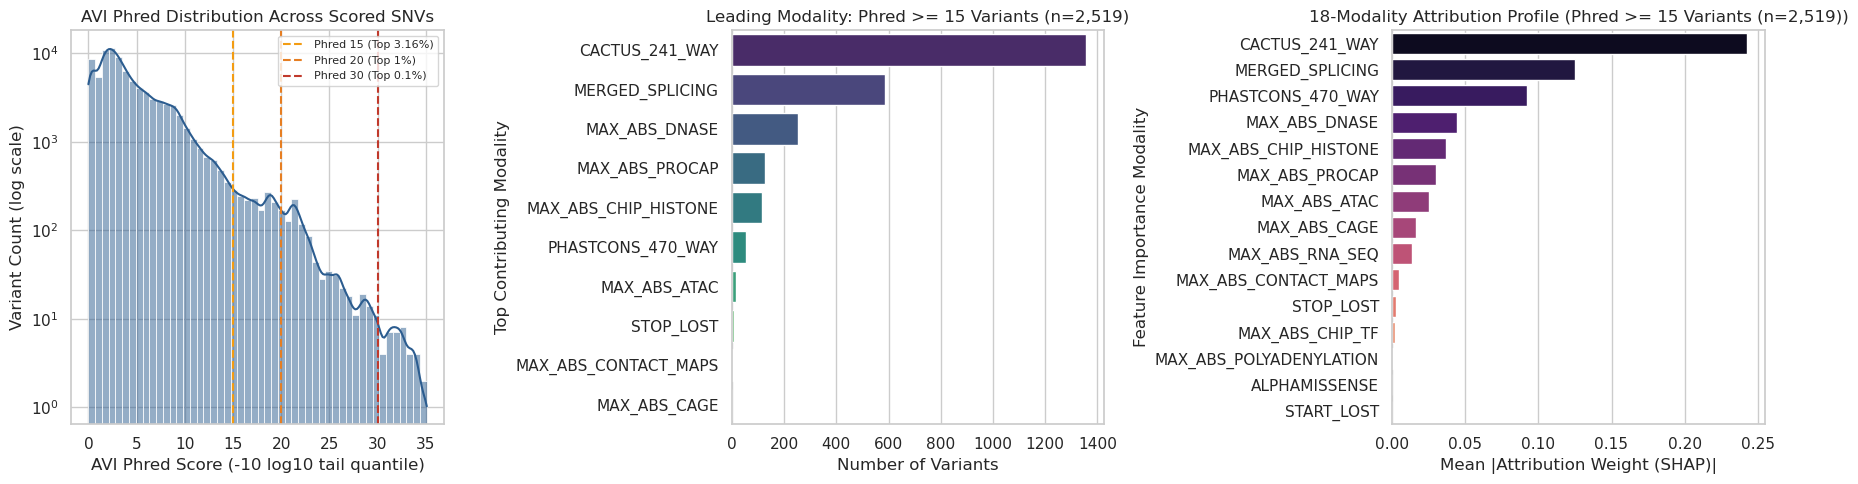

In [14]:
# @title Plot AVI Score Distributions & Top Driving Modalities
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. AVI Phred Histogram with threshold lines
ax0 = axes[0]
sns.histplot(core_df['avi_phred'].dropna(), bins=50, kde=True, color='#2b5c8f', ax=ax0)
for thresh, label, col in [
    (PHRED_MODERATE, 'Phred 15 (Top 3.16%)', '#f39c12'),
    (PHRED_HIGH, 'Phred 20 (Top 1%)', '#e67e22'),
    (PHRED_EXTREME, 'Phred 30 (Top 0.1%)', '#c0392b'),
]:
    ax0.axvline(thresh, color=col, linestyle='--', linewidth=1.5, label=label)
ax0.set_yscale('log')
ax0.set_xlabel('AVI Phred Score (-10 log10 tail quantile)')
ax0.set_ylabel('Variant Count (log scale)')
ax0.set_title('AVI Phred Distribution Across Scored SNVs')
ax0.legend(fontsize=8)

# 2. Top Modality Frequency among High-Impact Variants (Phred >= 15, fallback to top 5%)
ax1 = axes[1]
high_mask = core_df['avi_phred'] >= PHRED_MODERATE
if high_mask.sum() < 10:
    q95 = core_df['avi_phred'].quantile(0.95)
    high_sub = core_df[core_df['avi_phred'] >= q95]
    sub_label = f'Top 5% Variants (Phred >= {q95:.1f}, n={len(high_sub):,})'
else:
    high_sub = core_df[high_mask]
    sub_label = f'Phred >= {PHRED_MODERATE:.0f} Variants (n={len(high_sub):,})'

if 'top_modality' in high_sub.columns and not high_sub.empty:
    mod_counts = high_sub['top_modality'].value_counts().head(12)
    sns.barplot(
        x=mod_counts.values,
        y=mod_counts.index,
        hue=mod_counts.index,
        palette='viridis',
        legend=False,
        ax=ax1,
    )
    ax1.set_xlabel('Number of Variants')
    ax1.set_ylabel('Top Contributing Modality')
    ax1.set_title(f'Leading Modality: {sub_label}')

# 3. Mean |Feature Importance| across the 18 fi_* columns in high-impact subset
ax2 = axes[2]
fi_cols = ds_info['fi_cols']
if fi_cols and not high_sub.empty:
    mean_abs_fi = (
        high_sub[fi_cols]
        .abs()
        .mean()
        .rename(lambda c: c.removeprefix('fi_'))
        .sort_values(ascending=False)
        .head(15)
    )
    sns.barplot(
        x=mean_abs_fi.values,
        y=mean_abs_fi.index,
        hue=mean_abs_fi.index,
        palette='magma',
        legend=False,
        ax=ax2,
    )
    ax2.set_xlabel('Mean |Attribution Weight (SHAP)|')
    ax2.set_ylabel('Feature Importance Modality')
    ax2.set_title(f'18-Modality Attribution Profile ({sub_label})')

plt.tight_layout()
# plt.savefig(os.path.join(OUTPUT_DIR, 'avi_distributions_and_modalities.png'), dpi=300)
plt.show()


## 18-Modality Feature Importance Heatmap Across Top 35 Candidate Variants

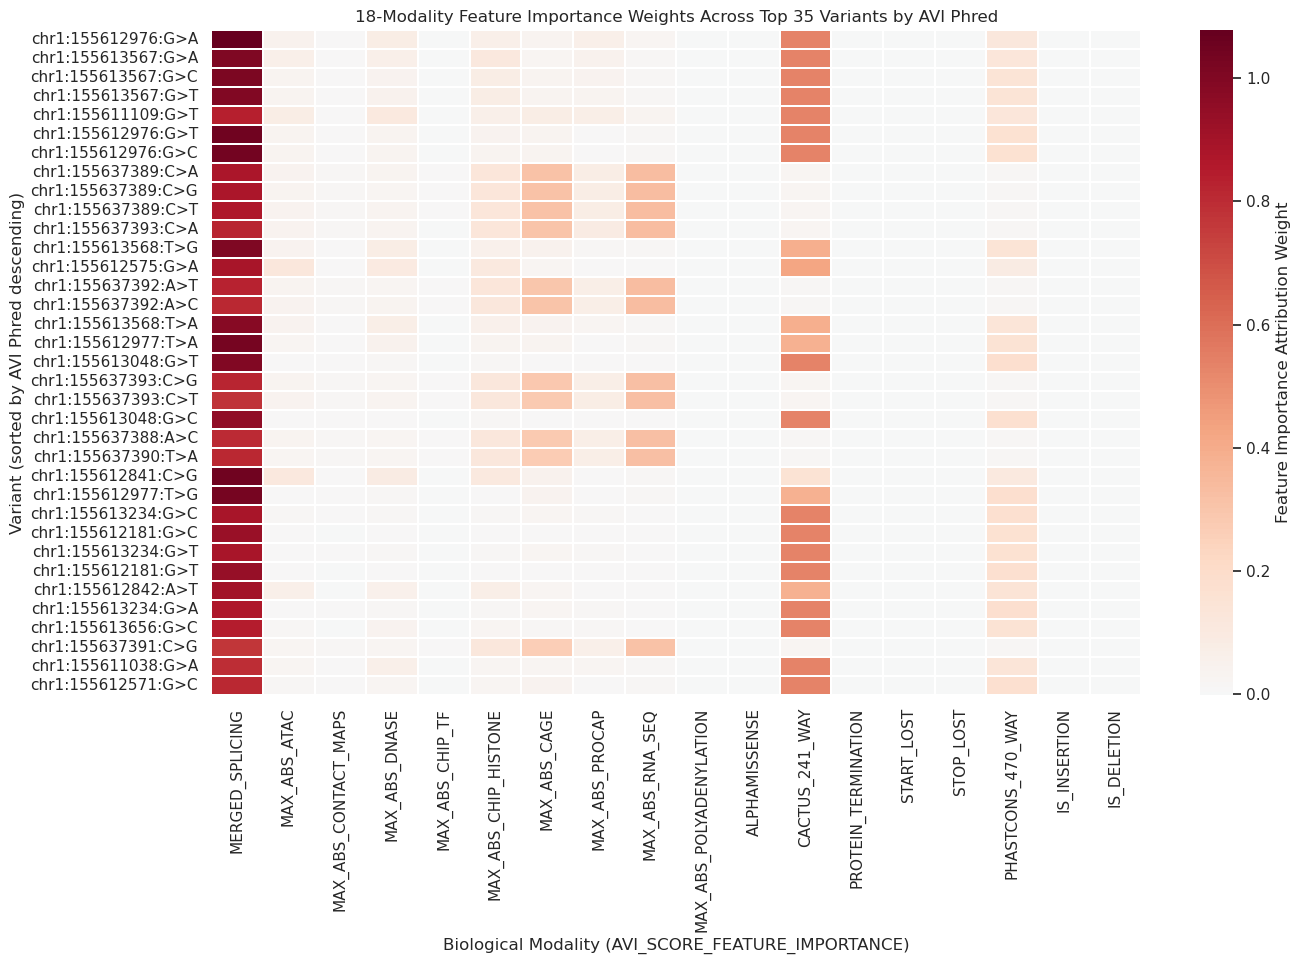

In [15]:
# @title 18-Modality Feature Importance Heatmap Across Top 35 Candidate Variants
top_n_heatmap = min(35, len(core_df))
top_fi_variants = (
    core_df.sort_values('avi_phred', ascending=False)
    .head(top_n_heatmap)
    .copy()
)

if ds_info['fi_cols'] and not top_fi_variants.empty:
    fi_matrix = top_fi_variants.set_index('variant')[ds_info['fi_cols']].copy()
    fi_matrix.columns = [c.removeprefix('fi_') for c in fi_matrix.columns]

    plt.figure(figsize=(14, max(6, 0.28 * len(fi_matrix))))
    sns.heatmap(
        fi_matrix,
        cmap='RdBu_r',
        center=0.0,
        linewidths=0.3,
        cbar_kws={'label': 'Feature Importance Attribution Weight'},
    )
    plt.title(f'18-Modality Feature Importance Weights Across Top {len(fi_matrix)} Variants by AVI Phred')
    plt.xlabel('Biological Modality (AVI_SCORE_FEATURE_IMPORTANCE)')
    plt.ylabel('Variant (sorted by AVI Phred descending)')
    plt.tight_layout()
    # plt.savefig(os.path.join(OUTPUT_DIR, 'top_variants_18modality_heatmap.png'), dpi=300)
    plt.show()


# GENCODE v46 `LMNA` Structural Annotation & Genomic Landscape

Next, we load GENCODE v46 annotations for `LMNA` (`ENSG00000160789`) from the local feather cache (`~/.cache/alphagenome/gencode.v46.annotation.gtf.gz.feather` or GCS fallback) to compute:
- Exact distance from each variant/region to the `LMNA` MANE Select Transcription Start Site (TSS)
- Distance to the nearest `LMNA` MANE Select exon and canonical splice site (donor/acceptor)
- Functional region classification (`Promoter [-2kb, +500bp]`, `Exonic / Splice Boundary (<=20bp)`, `Proximal Intronic / Flanking (<10kb)`, `Distal Intergenic / Enhancer (>=10kb)`)

## Annotate Variants & BED Regions with GENCODE v46 LMNA Exons, Splice Sites & TSS

In [16]:
# @title Annotate Variants & BED Regions with GENCODE v46 LMNA Exons, Splice Sites & TSS
GTF_FEATHER_URL = (
    'https://storage.googleapis.com/alphagenome/reference/gencode/'
    'hg38/gencode.v46.annotation.gtf.gz.feather'
)


def load_lmna_structure(gene_symbol: str = TARGET_GENE_SYMBOL) -> dict[str, Any]:
    """Loads GENCODE v46 annotations for LMNA (MANE Select exons, TSS, gene bounds)."""
    cache_path = os.path.expanduser(
        '~/.cache/alphagenome/gencode.v46.annotation.gtf.gz.feather'
    )
    gtf_df = None
    for candidate in (os.environ.get('ALPHAGENOME_GTF_PATH'), cache_path):
        if candidate and os.path.exists(candidate):
            gtf_df = pd.read_feather(candidate)
            break
    if gtf_df is None:
        try:
            gtf_df = pd.read_feather(GTF_FEATHER_URL)
            os.makedirs(os.path.dirname(cache_path), exist_ok=True)
            gtf_df.to_feather(cache_path)
        except Exception as e:
            print(f'Warning: Could not load GENCODE v46 feather ({e}). Using hg38 LMNA fallback coordinates.')
            return {
                'gene_symbol': gene_symbol,
                'chromosome': 'chr1',
                'gene_start': 156084461,
                'gene_end': 156140081,
                'strand': '+',
                'tss': 156084461,
                'exons_df': pd.DataFrame(),
            }

    gene_rows = gtf_df[gtf_df['gene_name'] == gene_symbol].copy()
    if gene_rows.empty:
        raise ValueError(f'Gene {gene_symbol} not found in GENCODE v46 GTF.')

    gene_feature = gene_rows[gene_rows['Feature'] == 'gene']
    if gene_feature.empty:
        gene_feature = gene_rows
    chrom = str(gene_feature['Chromosome'].iloc[0])
    g_start = int(gene_feature['Start'].min())
    g_end = int(gene_feature['End'].max())
    strand = str(gene_feature['Strand'].iloc[0])

    # Prefer MANE Select transcript for canonical exon numbering
    exon_rows = gene_rows[gene_rows['Feature'] == 'exon'].copy()
    if 'tag' in exon_rows.columns:
        mane_exons = exon_rows[
            exon_rows['tag'].fillna('').astype(str).str.contains('MANE_Select')
        ]
        if not mane_exons.empty:
            tx_id = mane_exons['transcript_id'].iloc[0]
            exon_rows = mane_exons[mane_exons['transcript_id'] == tx_id].copy()
    if not exon_rows.empty and 'transcript_id' in exon_rows.columns:
        # Pick transcript with most exons if MANE tag wasn't present
        top_tx = exon_rows['transcript_id'].value_counts().index[0]
        exon_rows = exon_rows[exon_rows['transcript_id'] == top_tx].copy()

    exon_rows = exon_rows.sort_values('Start', ascending=(strand != '-')).reset_index(drop=True)
    exon_rows['exon_number'] = np.arange(1, len(exon_rows) + 1)
    tss = int(exon_rows['Start'].min()) if strand != '-' else int(exon_rows['End'].max())

    exons_clean = pd.DataFrame({
        'exon_number': exon_rows['exon_number'].astype(int),
        'start': exon_rows['Start'].astype(int),
        'end': exon_rows['End'].astype(int),
        'width_bp': (exon_rows['End'] - exon_rows['Start']).astype(int),
        'transcript_id': exon_rows.get('transcript_id', pd.Series([''] * len(exon_rows))).astype(str),
    })

    return {
        'gene_symbol': gene_symbol,
        'chromosome': chrom,
        'gene_start': g_start,
        'gene_end': g_end,
        'strand': strand,
        'tss': tss,
        'exons_df': exons_clean,
    }


lmna_info = load_lmna_structure(TARGET_GENE_SYMBOL)
print(
    f"{lmna_info['gene_symbol']} ({lmna_info['chromosome']}:{lmna_info['gene_start']:,}-"
    f"{lmna_info['gene_end']:,}, strand {lmna_info['strand']}), "
    f"TSS = {lmna_info['tss']:,}, MANE exons = {len(lmna_info['exons_df'])}"
)


def annotate_positions_with_gene_structure(
    df: pd.DataFrame,
    gene_info: dict[str, Any] = lmna_info,
) -> pd.DataFrame:
    """Vectorized computation of signed distance to LMNA TSS and nearest exon/splice boundary."""
    out = df.copy()
    pos = out['position'].to_numpy(dtype=np.int64)
    tss = int(gene_info['tss'])
    strand = gene_info['strand']

    # Signed distance relative to transcription direction (+ = downstream, - = upstream)
    out['dist_to_tss_bp'] = (pos - tss) if strand != '-' else (tss - pos)

    exons_df = gene_info['exons_df']
    if not exons_df.empty:
        starts = exons_df['start'].to_numpy(dtype=np.int64)  # [E]
        ends = exons_df['end'].to_numpy(dtype=np.int64)      # [E]
        exon_nums = exons_df['exon_number'].to_numpy(dtype=np.int64)

        # Distance from each position [N, 1] to each exon interval [1, E]
        d_start = starts[None, :] - pos[:, None]  # >0 if pos < start
        d_end = pos[:, None] - ends[None, :]      # >0 if pos > end
        dist_mat = np.maximum(0, np.maximum(d_start, d_end))
        nearest_idx = np.argmin(dist_mat, axis=1)
        out['dist_to_nearest_exon_bp'] = dist_mat[np.arange(len(pos)), nearest_idx]
        out['nearest_exon_number'] = exon_nums[nearest_idx]

        # Distance to nearest splice boundary (internal exon ends/starts)
        splice_coords = np.unique(np.concatenate([starts[1:], ends[:-1]]))
        if splice_coords.size > 0:
            sp_dist = np.min(np.abs(pos[:, None] - splice_coords[None, :]), axis=1)
        else:
            sp_dist = out['dist_to_nearest_exon_bp'].to_numpy()
        out['dist_to_splice_site_bp'] = sp_dist
    else:
        out['dist_to_nearest_exon_bp'] = np.nan
        out['nearest_exon_number'] = -1
        out['dist_to_splice_site_bp'] = np.nan

    # Classify genomic context relative to LMNA
    g_start, g_end = int(gene_info['gene_start']), int(gene_info['gene_end'])
    in_promoter = (out['dist_to_tss_bp'] >= -2000) & (out['dist_to_tss_bp'] <= 500)
    near_splice = out['dist_to_splice_site_bp'] <= 20
    in_exon = out['dist_to_nearest_exon_bp'] == 0
    in_gene_body = (pos >= g_start) & (pos <= g_end)
    proximal = out['dist_to_tss_bp'].abs() <= 10_000

    out['lmna_region_class'] = np.select(
        [in_exon, near_splice, in_promoter, in_gene_body, proximal],
        [
            'LMNA Exonic',
            'Splice Site Proximal (<=20bp)',
            'LMNA Promoter [-2kb, +500bp]',
            'LMNA Intronic',
            'Proximal Flanking (<=10kb)',
        ],
        default='Distal Intergenic / Enhancer (>10kb)',
    )
    return out


core_df = annotate_positions_with_gene_structure(core_df, lmna_info)
display(
    core_df.groupby('lmna_region_class')
    .agg(
        n_variants=('variant', 'count'),
        max_avi_phred=('avi_phred', 'max'),
        mean_avi_phred=('avi_phred', 'mean'),
        n_phred_ge_15=('avi_phred', lambda s: int((s >= PHRED_MODERATE).sum())),
        n_phred_ge_20=('avi_phred', lambda s: int((s >= PHRED_HIGH).sum())),
    )
    .sort_values('max_avi_phred', ascending=False)
)


LMNA (chr1:156,082,571-156,140,081, strand +), TSS = 156,114,710, MANE exons = 12


,n_variants,max_avi_phred,mean_avi_phred,n_phred_ge_15,n_phred_ge_20
lmna_region_class,,,,,
Distal Intergenic / Enhancer (>10kb),85770,35.103901,4.580422,2519,909


##  Plot 1 Mb Genomic Locus View of AVI Phred Scores & LMNA Exon Structure

/tmp/ipykernel_1400212/1969787987.py:64: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


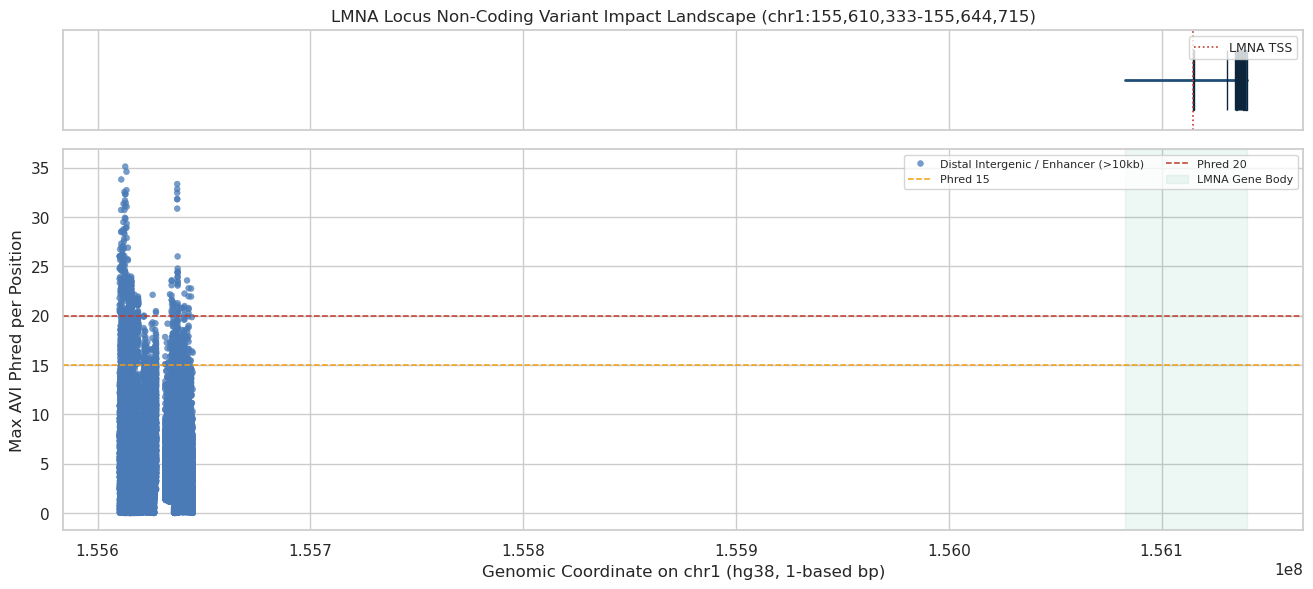

In [17]:
# @title Plot 1 Mb Genomic Locus View of AVI Phred Scores & LMNA Exon Structure
fig, (ax_gene, ax_avi) = plt.subplots(
    2,
    1,
    figsize=(16, 6.5),
    sharex=True,
    gridspec_kw={'height_ratios': [1.0, 3.8], 'hspace': 0.08},
)

# Top panel: LMNA gene & exon model
g_start, g_end = lmna_info['gene_start'], lmna_info['gene_end']
ax_gene.plot([g_start, g_end], [0.5, 0.5], color='#1f4e78', linewidth=2.0, zorder=1)
exons_df = lmna_info['exons_df']
if not exons_df.empty:
    for _, ex in exons_df.iterrows():
        rect = mpatches.Rectangle(
            (ex['start'], 0.2),
            max(150, ex['end'] - ex['start']),
            0.6,
            facecolor='#1f4e78',
            edgecolor='#0d253a',
            zorder=2,
        )
        ax_gene.add_patch(rect)
ax_gene.axvline(lmna_info['tss'], color='#c0392b', linestyle=':', linewidth=1.2, label='LMNA TSS')
ax_gene.set_ylim(0, 1)
ax_gene.set_yticks([])
ax_gene.set_title(
    f"{TARGET_GENE_SYMBOL} Locus Non-Coding Variant Impact Landscape ({lmna_info['chromosome']}:{int(core_df['position'].min()):,}-{int(core_df['position'].max()):,})"
)
ax_gene.legend(loc='upper right', fontsize=9)

# Bottom panel: Max AVI Phred per genomic position (or per 250 bp bin if dense)
pos_max_df = (
    core_df.groupby(['position', 'lmna_region_class'], as_index=False)['avi_phred']
    .max()
)
palette_map = {
    'LMNA Promoter [-2kb, +500bp]': '#d95f02',
    'Splice Site Proximal (<=20bp)': '#e7298a',
    'LMNA Exonic': '#7570b3',
    'LMNA Intronic': '#1b9e77',
    'Proximal Flanking (<=10kb)': '#66a61e',
    'Distal Intergenic / Enhancer (>10kb)': '#4a7bb7',
}
sns.scatterplot(
    data=pos_max_df,
    x='position',
    y='avi_phred',
    hue='lmna_region_class',
    palette=palette_map,
    s=18,
    alpha=0.75,
    edgecolor=None,
    ax=ax_avi,
)
ax_avi.axhline(PHRED_MODERATE, color='#f39c12', linestyle='--', linewidth=1.1, label='Phred 15')
ax_avi.axhline(PHRED_HIGH, color='#c0392b', linestyle='--', linewidth=1.1, label='Phred 20')
ax_avi.axvspan(g_start, g_end, color='#1b9e77', alpha=0.08, label='LMNA Gene Body')
ax_avi.set_xlabel(f'Genomic Coordinate on {lmna_info["chromosome"]} (hg38, 1-based bp)')
ax_avi.set_ylabel('Max AVI Phred per Position')
ax_avi.legend(loc='upper right', fontsize=8, ncol=2)

plt.tight_layout()
# plt.savefig(os.path.join(OUTPUT_DIR, 'lmna_1mb_locus_avi_landscape.png'), dpi=300)
plt.show()


## 5. AlphaGenome Atlas Deep-Linking & Top Candidate Variant / BED Hotspot Tables

Every prioritized variant or BED region includes a clickable deep-link to the [AlphaGenome Atlas](https://deepmind.google.com/science/alphagenome/atlas) following the `alphagenome-atlas-website-links` URL specification:
- **Single Variant (`m=variant`)**: 1-based `chr:pos:ref>alt` with `lItems=avi,section:RNA_SEQ,section:DNASE,section:CHIP_TF`
- **Genomic Locus (`m=locus`)**: 1-based closed `chr:start_1based-end_1based` converted from 0-based half-open BED coordinates (`start_1based = bed_start + 1`, `end_1based = bed_end`).

In [9]:
# @title AlphaGenome Atlas URL Builders & Top Variants / BED Region Hotspot Tables
ATLAS_BASE_URL = 'https://deepmind.google.com/science/alphagenome/atlas'


def build_atlas_variant_url(
    variant_str: str,
    biosample: str | None = None,
    modalities: tuple[str, ...] = ('RNA_SEQ', 'DNASE', 'CHIP_TF'),
    tfs: tuple[str, ...] = (),
) -> str:
    """Constructs an AlphaGenome Atlas single-variant exploration deep-link (1-based chr:pos:ref>alt)."""
    l_items = ['avi'] + [f'section:{m}' for m in modalities]
    params: dict[str, str] = {
        'q': str(variant_str),
        'm': 'variant',
        'lItems': ','.join(l_items),
    }
    filters = []
    if biosample:
        filters.append(f'BIOSAMPLE_NAME:{biosample}')
    if tfs:
        # Mandatory Multi-Modality Filter Rule: include SCORER_MODALITY when filtering TFs
        filters.extend(['SCORER_MODALITY:RNA-seq', 'SCORER_MODALITY:DNase'])
        filters.extend([f'ASSAY_TRANSCRIPTOR_FACTOR:{tf}' for tf in tfs])
    if filters:
        params['f'] = ','.join(filters)
    return f'{ATLAS_BASE_URL}?{urllib.parse.urlencode(params, safe=":,>")}'


def build_atlas_locus_url(
    chrom: str,
    bed_start_0based: int,
    bed_end_0based: int,
    biosample: str | None = None,
    modalities: tuple[str, ...] = ('RNA_SEQ', 'DNASE', 'CHIP_TF'),
) -> str:
    """Constructs an AlphaGenome Atlas locus deep-link (converts 0-based BED to 1-based closed chr:start-end)."""
    start_1based = int(bed_start_0based) + 1
    end_1based = int(bed_end_0based)
    l_items = ['avi'] + [f'section:{m}' for m in modalities]
    params: dict[str, str] = {
        'q': f'{chrom}:{start_1based}-{end_1based}',
        'm': 'locus',
        'lItems': ','.join(l_items),
    }
    if biosample:
        params['f'] = f'BIOSAMPLE_NAME:{biosample}'
    return f'{ATLAS_BASE_URL}?{urllib.parse.urlencode(params, safe=":,-")}'


# 1. Rank Top 25 Variants by AVI Phred
top_variants_df = (
    core_df.sort_values('avi_phred', ascending=False)
    .head(25)
    .reset_index(drop=True)
    .copy()
)
top_variants_df.insert(0, 'rank', np.arange(1, len(top_variants_df) + 1))
top_variants_df['atlas_url'] = top_variants_df['variant'].map(build_atlas_variant_url)
top_variants_df['atlas_link'] = top_variants_df['atlas_url'].map(
    lambda u: f'<a href="{u}" target="_blank">Open in Atlas</a>'
)

top_variants_df.to_csv(
    os.path.join(OUTPUT_DIR, 'top_avi_variants_annotated.csv'), index=False
)

display(Markdown('### Top 25 Prioritized Non-Coding Variants by AVI Phred'))
display_cols = [
    c for c in (
        'rank',
        'variant',
        'region_str',
        'avi_phred',
        'avi_raw',
        'top_percentile',
        'top_modality',
        'top_feature_importance',
        'lmna_region_class',
        'dist_to_tss_bp',
        'dist_to_nearest_exon_bp',
        'nearest_exon_number',
        'atlas_link',
    )
    if c in top_variants_df.columns
]
display(HTML(top_variants_df[display_cols].to_html(escape=False, index=False)))


### Top 25 Prioritized Non-Coding Variants by AVI Phred

rank,variant,region_str,avi_phred,avi_raw,top_percentile,top_modality,top_feature_importance,lmna_region_class,dist_to_tss_bp,dist_to_nearest_exon_bp,nearest_exon_number,atlas_link
1,chr1:155612976:G>A,chr1:155612975-155613048,35.103901,2.032106,0.030875,MERGED_SPLICING,1.077206,Distal Intergenic / Enhancer (>10kb),-501734,501734,1,"A&m=variant&lItems=avi,section:RNA_SEQ,section:DNASE,section:CHIP_TF"" target=""_blank"">Open in Atlas"
2,chr1:155613567:G>A,chr1:155613566-155613656,34.580841,1.970103,0.034827,MERGED_SPLICING,1.002462,Distal Intergenic / Enhancer (>10kb),-501143,501143,1,"A&m=variant&lItems=avi,section:RNA_SEQ,section:DNASE,section:CHIP_TF"" target=""_blank"">Open in Atlas"
3,chr1:155613567:G>C,chr1:155613566-155613656,34.056366,1.906824,0.039297,MERGED_SPLICING,1.011148,Distal Intergenic / Enhancer (>10kb),-501143,501143,1,"C&m=variant&lItems=avi,section:RNA_SEQ,section:DNASE,section:CHIP_TF"" target=""_blank"">Open in Atlas"
4,chr1:155613567:G>T,chr1:155613566-155613656,33.854301,1.882952,0.041169,MERGED_SPLICING,0.997697,Distal Intergenic / Enhancer (>10kb),-501143,501143,1,"T&m=variant&lItems=avi,section:RNA_SEQ,section:DNASE,section:CHIP_TF"" target=""_blank"">Open in Atlas"
5,chr1:155611109:G>T,chr1:155611108-155611215,33.796841,1.876488,0.041717,MERGED_SPLICING,0.836719,Distal Intergenic / Enhancer (>10kb),-503601,503601,1,"T&m=variant&lItems=avi,section:RNA_SEQ,section:DNASE,section:CHIP_TF"" target=""_blank"">Open in Atlas"
6,chr1:155612976:G>T,chr1:155612975-155613048,33.787540,1.875476,0.041807,MERGED_SPLICING,1.046618,Distal Intergenic / Enhancer (>10kb),-501734,501734,1,"T&m=variant&lItems=avi,section:RNA_SEQ,section:DNASE,section:CHIP_TF"" target=""_blank"">Open in Atlas"
7,chr1:155612976:G>C,chr1:155612975-155613048,33.536728,1.846955,0.044292,MERGED_SPLICING,1.038154,Distal Intergenic / Enhancer (>10kb),-501734,501734,1,"C&m=variant&lItems=avi,section:RNA_SEQ,section:DNASE,section:CHIP_TF"" target=""_blank"">Open in Atlas"
8,chr1:155637389:C>A,chr1:155631715-155659659,33.333496,1.824431,0.046414,MERGED_SPLICING,0.879704,Distal Intergenic / Enhancer (>10kb),-477321,477321,1,"A&m=variant&lItems=avi,section:RNA_SEQ,section:DNASE,section:CHIP_TF"" target=""_blank"">Open in Atlas"
9,chr1:155637389:C>G,chr1:155631715-155659659,33.209248,1.810929,0.047761,MERGED_SPLICING,0.877619,Distal Intergenic / Enhancer (>10kb),-477321,477321,1,"G&m=variant&lItems=avi,section:RNA_SEQ,section:DNASE,section:CHIP_TF"" target=""_blank"">Open in Atlas"
10,chr1:155637389:C>T,chr1:155631715-155659659,33.161812,1.805815,0.048286,MERGED_SPLICING,0.868115,Distal Intergenic / Enhancer (>10kb),-477321,477321,1,"T&m=variant&lItems=avi,section:RNA_SEQ,section:DNASE,section:CHIP_TF"" target=""_blank"">Open in Atlas"


## Rank BED Region Hotspots by Variant Impact Density

In [38]:
# @title Rank BED Region Hotspots by Variant Impact Density
if {'region_id', 'region_str', 'bed_start', 'bed_end'}.issubset(core_df.columns):
    region_hotspots_df = (
        core_df.groupby(
            ['region_id', 'chromosome', 'bed_start', 'bed_end', 'region_str'],
            as_index=False,
        )
        .agg(
            n_variants=('variant', 'count'),
            max_avi_phred=('avi_phred', 'max'),
            mean_avi_phred=('avi_phred', 'mean'),
            median_avi_phred=('avi_phred', 'median'),
            n_phred_ge_15=('avi_phred', lambda s: int((s >= PHRED_MODERATE).sum())),
            n_phred_ge_20=('avi_phred', lambda s: int((s >= PHRED_HIGH).sum())),
            top_variant=('variant', lambda s: core_df.loc[s.index].sort_values('avi_phred', ascending=False)['variant'].iloc[0]),
            dominant_modality=('top_modality', lambda s: s.mode().iloc[0] if not s.dropna().empty else 'N/A'),
            region_class=('lmna_region_class', lambda s: s.mode().iloc[0] if not s.dropna().empty else 'N/A'),
            min_dist_to_tss_bp=('dist_to_tss_bp', lambda s: int(s.iloc[np.argmin(np.abs(s))])),
        )
        .sort_values(['max_avi_phred', 'n_phred_ge_15'], ascending=[False, False])
        .reset_index(drop=True)
    )
    region_hotspots_df['width_bp'] = region_hotspots_df['bed_end'] - region_hotspots_df['bed_start']
    region_hotspots_df['pct_phred_ge_15'] = (
        100.0 * region_hotspots_df['n_phred_ge_15'] / region_hotspots_df['n_variants'].clip(lower=1)
    )
    region_hotspots_df['atlas_locus_url'] = [
        build_atlas_locus_url(c, s, e)
        for c, s, e in zip(
            region_hotspots_df['chromosome'],
            region_hotspots_df['bed_start'],
            region_hotspots_df['bed_end'],
        )
    ]
    region_hotspots_df['atlas_locus_link'] = region_hotspots_df['atlas_locus_url'].map(
        lambda u: f'<a href="{u}" target="_blank">View Locus in Atlas</a>'
    )

    region_hotspots_df.to_csv(
        os.path.join(OUTPUT_DIR, 'bed_region_hotspot_summary.csv'), index=False
    )

    display(Markdown('### Top 20 BED Region Regulatory Hotspots'))
    reg_disp_cols = [
        'region_id',
        'region_str',
        'width_bp',
        'region_class',
        'min_dist_to_tss_bp',
        'max_avi_phred',
        'mean_avi_phred',
        'n_phred_ge_15',
        'pct_phred_ge_15',
        'n_phred_ge_20',
        'top_variant',
        'dominant_modality',
        'atlas_locus_link',
    ]
    display(HTML(region_hotspots_df.head(20)[reg_disp_cols].to_html(escape=False, index=False)))


### Top 20 BED Region Regulatory Hotspots

region_id,region_str,width_bp,region_class,min_dist_to_tss_bp,max_avi_phred,mean_avi_phred,n_phred_ge_15,pct_phred_ge_15,n_phred_ge_20,top_variant,dominant_modality,atlas_locus_link
14033,chr1:155612975-155613048,73,Distal Intergenic / Enhancer (>10kb),-501662,35.103901,6.168328,19,8.675799,17,chr1:155612976:G>A,CACTUS_241_WAY,View Locus in Atlas
14035,chr1:155613566-155613656,90,Distal Intergenic / Enhancer (>10kb),-501054,34.580841,10.661201,64,23.703704,28,chr1:155613567:G>A,MAX_ABS_DNASE,View Locus in Atlas
14026,chr1:155611108-155611215,107,Distal Intergenic / Enhancer (>10kb),-503495,33.796841,6.576154,35,10.903427,22,chr1:155611109:G>T,CACTUS_241_WAY,View Locus in Atlas
14038,chr1:155631715-155659659,27944,Distal Intergenic / Enhancer (>10kb),-472995,33.333496,4.700310,430,1.433333,84,chr1:155637389:C>A,MAX_ABS_DNASE,View Locus in Atlas
14032,chr1:155612570-155612843,273,Distal Intergenic / Enhancer (>10kb),-501867,32.528877,6.592190,83,10.134310,43,chr1:155612575:G>A,CACTUS_241_WAY,View Locus in Atlas
14034,chr1:155613233-155613424,191,Distal Intergenic / Enhancer (>10kb),-501286,31.432285,4.942160,35,6.108202,17,chr1:155613234:G>C,CACTUS_241_WAY,View Locus in Atlas
14030,chr1:155612100-155612181,81,Distal Intergenic / Enhancer (>10kb),-502529,31.338272,5.020236,23,9.465021,19,chr1:155612181:G>C,CACTUS_241_WAY,View Locus in Atlas
14025,chr1:155610560-155611038,478,Distal Intergenic / Enhancer (>10kb),-503672,30.707222,5.892913,69,4.811715,32,chr1:155611038:G>A,MERGED_SPLICING,View Locus in Atlas
14031,chr1:155612316-155612417,101,Distal Intergenic / Enhancer (>10kb),-502293,28.592880,6.271709,28,9.240924,24,chr1:155612317:G>T,MERGED_SPLICING,View Locus in Atlas
14037,chr1:155614270-155627590,13320,Distal Intergenic / Enhancer (>10kb),-487120,26.883636,4.188699,1499,3.751251,503,chr1:155614271:T>G,CACTUS_241_WAY,View Locus in Atlas


# `LMNA` Gene-Level Expression & Splicing Deep Dive (`RNA_SEQ` & `SPLICE_JUNCTIONS`)

In `atlas.ipynb`, gene-level scorers were specifically filtered to `LMNA`, producing columns with suffix `__LMNA` (e.g., `RNA_SEQ__t0000__LMNA`) or `__LMNA_<junction_start>_<junction_end>` (e.g., `SPLICE_JUNCTIONS__t0000__LMNA_156105104_156105680`).

> **Mandatory Splicing & RNA-seq Co-Plotting Rule**: Splicing mutations frequently activate cryptic splice junctions and trigger nonsense-mediated decay (NMD) or alter total transcript output. Here we jointly load and co-plot continuous `RNA_SEQ` expression changes alongside `SPLICE_JUNCTIONS` (and `SPLICE_SITES` / `SPLICE_SITE_USAGE`) across the `LMNA` locus.

## Load LMNA Gene-Level Track Columns & Co-Plot Splicing vs. RNA-Seq Effects

Loaded LMNA gene-level & splicing slice:
  - RNA_SEQ__t*__LMNA columns          : 371
  - SPLICE_JUNCTIONS__t*__LMNA* columns: 0
  - SPLICE_SITES / SPLICE_SITE_USAGE   : 0


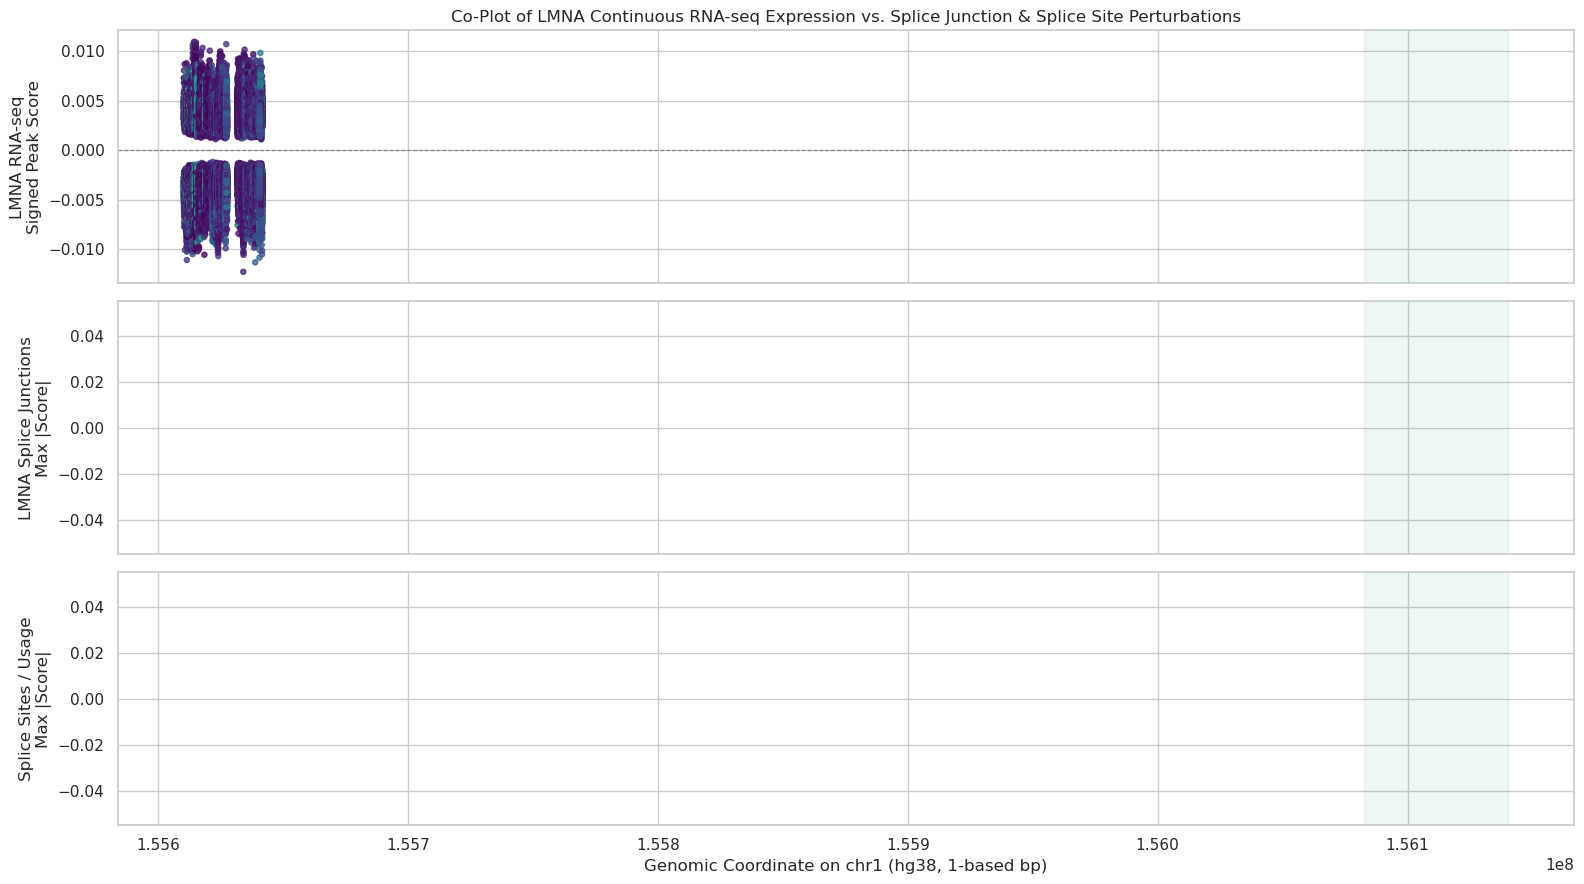

In [39]:
# @title Load LMNA Gene-Level Track Columns & Co-Plot Splicing vs. RNA-Seq Effects
gene_track_cols = ds_info['gene_track_cols']
splicing_non_gene_cols = schema_tracks_df.loc[
    schema_tracks_df['scorer'].isin(['SPLICE_SITES', 'SPLICE_SITE_USAGE']),
    'parquet_column',
].tolist()

lmna_load_cols = ['variant', 'position', 'avi_phred', 'top_modality', 'lmna_region_class'] + gene_track_cols + splicing_non_gene_cols
lmna_tracks_df = load_variant_subset(columns=lmna_load_cols)

rna_lmna_cols = [c for c in gene_track_cols if c.startswith('RNA_SEQ__')]
sj_lmna_cols = [c for c in gene_track_cols if c.startswith('SPLICE_JUNCTIONS__')]
ss_cols = [c for c in splicing_non_gene_cols if c in lmna_tracks_df.columns]

print(f'Loaded LMNA gene-level & splicing slice:')
print(f'  - RNA_SEQ__t*__LMNA columns          : {len(rna_lmna_cols):,}')
print(f'  - SPLICE_JUNCTIONS__t*__LMNA* columns: {len(sj_lmna_cols):,}')
print(f'  - SPLICE_SITES / SPLICE_SITE_USAGE   : {len(ss_cols):,}')

# Compute per-variant summary metrics across LMNA RNA-seq and Splice Junction tracks
if rna_lmna_cols:
    rna_mat = lmna_tracks_df[rna_lmna_cols].to_numpy(dtype=np.float32)
    lmna_tracks_df['lmna_rnaseq_max_abs'] = np.nanmax(np.abs(rna_mat), axis=1)
    lmna_tracks_df['lmna_rnaseq_mean'] = np.nanmean(rna_mat, axis=1)
    max_rna_idx = np.nanargmax(np.where(np.isnan(rna_mat), -1.0, np.abs(rna_mat)), axis=1)
    lmna_tracks_df['lmna_rnaseq_signed_peak'] = rna_mat[np.arange(len(lmna_tracks_df)), max_rna_idx]
    lmna_tracks_df['lmna_rnaseq_top_col'] = [rna_lmna_cols[i] for i in max_rna_idx]
else:
    lmna_tracks_df['lmna_rnaseq_max_abs'] = np.nan
    lmna_tracks_df['lmna_rnaseq_signed_peak'] = np.nan

if sj_lmna_cols:
    sj_mat = lmna_tracks_df[sj_lmna_cols].to_numpy(dtype=np.float32)
    lmna_tracks_df['lmna_sj_max_abs'] = np.nanmax(np.abs(sj_mat), axis=1)
    max_sj_idx = np.nanargmax(np.where(np.isnan(sj_mat), -1.0, np.abs(sj_mat)), axis=1)
    lmna_tracks_df['lmna_sj_signed_peak'] = sj_mat[np.arange(len(lmna_tracks_df)), max_sj_idx]
    lmna_tracks_df['lmna_sj_top_col'] = [sj_lmna_cols[i] for i in max_sj_idx]
else:
    lmna_tracks_df['lmna_sj_max_abs'] = np.nan
    lmna_tracks_df['lmna_sj_signed_peak'] = np.nan

if ss_cols:
    ss_mat = lmna_tracks_df[ss_cols].to_numpy(dtype=np.float32)
    lmna_tracks_df['splice_site_max_abs'] = np.nanmax(np.abs(ss_mat), axis=1)
else:
    lmna_tracks_df['splice_site_max_abs'] = np.nan

# Co-plot continuous LMNA RNA-seq expression effect alongside Splice Junction / Splice Site effects
fig, axes = plt.subplots(3, 1, figsize=(16, 9), sharex=True)

axes[0].scatter(
    lmna_tracks_df['position'],
    lmna_tracks_df['lmna_rnaseq_signed_peak'],
    c=lmna_tracks_df['avi_phred'],
    cmap='viridis',
    s=14,
    alpha=0.75,
)
axes[0].axhline(0, color='gray', linestyle='--', linewidth=0.8)
axes[0].set_ylabel('LMNA RNA-seq\nSigned Peak Score')
axes[0].set_title('Co-Plot of LMNA Continuous RNA-seq Expression vs. Splice Junction & Splice Site Perturbations')

axes[1].scatter(
    lmna_tracks_df['position'],
    lmna_tracks_df['lmna_sj_max_abs'],
    c='#d95f02',
    s=14,
    alpha=0.75,
)
axes[1].set_ylabel('LMNA Splice Junctions\nMax |Score|')

axes[2].scatter(
    lmna_tracks_df['position'],
    lmna_tracks_df['splice_site_max_abs'],
    c='#7570b3',
    s=14,
    alpha=0.75,
)
axes[2].set_ylabel('Splice Sites / Usage\nMax |Score|')
axes[2].set_xlabel(f'Genomic Coordinate on {lmna_info["chromosome"]} (hg38, 1-based bp)')

for ax in axes:
    ax.axvspan(lmna_info['gene_start'], lmna_info['gene_end'], color='#1b9e77', alpha=0.08)

plt.tight_layout()
# plt.savefig(os.path.join(OUTPUT_DIR, 'lmna_rnaseq_and_splicing_coplot.png'), dpi=300)
plt.show()


## Summarize Top Perturbed LMNA Splice Junctions & Biosamples

In [40]:
# @title Summarize Top Perturbed LMNA Splice Junctions & Biosamples
if sj_lmna_cols:
    sj_schema_sub = schema_tracks_df[schema_tracks_df['parquet_column'].isin(sj_lmna_cols)].copy()
    sj_max_per_col = lmna_tracks_df[sj_lmna_cols].abs().max().rename('max_abs_score')
    sj_schema_sub = sj_schema_sub.merge(
        sj_max_per_col, left_on='parquet_column', right_index=True, how='left'
    )

    junction_summary = (
        sj_schema_sub.groupby(['junction_start', 'junction_end', 'gene_suffix'], dropna=False)
        .agg(
            n_tracks=('parquet_column', 'count'),
            max_abs_junction_score=('max_abs_score', 'max'),
            top_biosample=(
                'biosample_name',
                lambda s: sj_schema_sub.loc[s.index].sort_values('max_abs_score', ascending=False)['biosample_name'].iloc[0],
            ),
        )
        .reset_index()
        .sort_values('max_abs_junction_score', ascending=False)
    )
    display(Markdown('### LMNA Splice Junctions Ranked by Peak Variant Perturbation'))
    display(junction_summary.head(15))


# Heart & Cardiac Tissue-Specific Track Analysis

Because `LMNA` mutations and regulatory perturbations are major drivers of dilated cardiomyopathy and cardiac conduction disease (as explored in `alphagenome2.ipynb` across `UBERON:0000948`, `UBERON:0002084`, `CL:0000746`, and `CL:0002098`), we isolate all cardiac experimental tracks and compare cardiac vs. non-cardiac track effect sizes across modalities (`RNA_SEQ`, `ATAC`, `DNASE`, `CHIP_HISTONE`, `CHIP_TF`, `SPLICE_JUNCTIONS`).

## Selectively Load Cardiac Tracks & Identify Heart-Prioritized Variants

In [41]:
# @title Selectively Load Cardiac Tracks & Identify Heart-Prioritized Variants
cardiac_track_meta = schema_tracks_df[schema_tracks_df['is_cardiac'].fillna(False)].copy()
cardiac_cols = cardiac_track_meta['parquet_column'].tolist()

print(f'Identified {len(cardiac_cols):,} cardiac track columns across {cardiac_track_meta["scorer"].nunique()} scorers:')
display(
    cardiac_track_meta.groupby(['scorer', 'biosample_name', 'ontology_curie'], dropna=False)
    .size()
    .reset_index(name='n_track_columns')
    .sort_values('n_track_columns', ascending=False)
    .head(20)
)

if cardiac_cols:
    cardiac_df = load_variant_subset(
        columns=['variant', 'region_str', 'position', 'avi_phred', 'top_modality', 'lmna_region_class', 'dist_to_tss_bp'] + cardiac_cols
    )

    # Compute per-scorer max |score| across cardiac tracks for each variant
    scorer_max_cols = []
    for scorer_name, grp in cardiac_track_meta.groupby('scorer'):
        s_cols = [c for c in grp['parquet_column'] if c in cardiac_df.columns]
        if not s_cols:
            continue
        col_out = f'cardiac_max_abs_{scorer_name}'
        cardiac_df[col_out] = np.nanmax(np.abs(cardiac_df[s_cols].to_numpy(dtype=np.float32)), axis=1)
        scorer_max_cols.append(col_out)

    # Identify the single strongest cardiac track column & value per variant
    c_mat = np.abs(cardiac_df[cardiac_cols].to_numpy(dtype=np.float32))
    c_mat_clean = np.where(np.isnan(c_mat), -1.0, c_mat)
    top_c_idx = np.argmax(c_mat_clean, axis=1)
    cardiac_df['cardiac_peak_abs_score'] = c_mat[np.arange(len(cardiac_df)), top_c_idx]
    cardiac_df['cardiac_peak_column'] = [cardiac_cols[i] for i in top_c_idx]

    col_to_meta = cardiac_track_meta.set_index('parquet_column')[
        ['scorer', 'track_name', 'biosample_name', 'ontology_curie', 'transcription_factor', 'histone_mark']
    ]
    cardiac_summary_df = (
        cardiac_df[
            ['variant', 'region_str', 'position', 'avi_phred', 'top_modality', 'lmna_region_class', 'dist_to_tss_bp', 'cardiac_peak_abs_score', 'cardiac_peak_column']
            + scorer_max_cols
        ]
        .merge(col_to_meta, left_on='cardiac_peak_column', right_index=True, how='left')
        .sort_values(['avi_phred', 'cardiac_peak_abs_score'], ascending=[False, False])
        .reset_index(drop=True)
    )
    cardiac_summary_df['atlas_url'] = cardiac_summary_df['variant'].map(
        lambda v: build_atlas_variant_url(v, modalities=('RNA_SEQ', 'DNASE', 'CHIP_TF', 'CHIP_HISTONE'))
    )
    cardiac_summary_df['atlas_link'] = cardiac_summary_df['atlas_url'].map(
        lambda u: f'<a href="{u}" target="_blank">Open in Atlas</a>'
    )

    cardiac_summary_df.head(100).to_csv(
        os.path.join(OUTPUT_DIR, 'lmna_cardiac_top_variants.csv'), index=False
    )

    display(Markdown('### Top 20 Variants Ranked by AVI Phred & Cardiac Track Perturbation'))
    c_disp = [
        'variant',
        'region_str',
        'avi_phred',
        'top_modality',
        'lmna_region_class',
        'dist_to_tss_bp',
        'cardiac_peak_abs_score',
        'scorer',
        'biosample_name',
        'ontology_curie',
        'histone_mark',
        'transcription_factor',
        'atlas_link',
    ]
    display(HTML(cardiac_summary_df.head(20)[[c for c in c_disp if c in cardiac_summary_df.columns]].to_html(escape=False, index=False)))


Identified 110 cardiac track columns across 6 scorers:


,scorer,biosample_name,ontology_curie,n_track_columns
21,CHIP_HISTONE,left ventricle myocardium inferior,NTR:0000493,6
20,CHIP_HISTONE,heart right ventricle,UBERON:0002080,6
19,CHIP_HISTONE,heart left ventricle,UBERON:0002084,6
16,CHIP_HISTONE,cardiac muscle cell,CL:0000746,5
22,CHIP_HISTONE,right atrium auricular region,UBERON:0006631,5
18,CHIP_HISTONE,heart,UBERON:0000948,4
23,CHIP_HISTONE,right cardiac atrium,UBERON:0002078,3
56,RNA_SEQ,heart right ventricle,UBERON:0002080,2
63,RNA_SEQ,right atrium auricular region,UBERON:0006631,2
8,CAGE,cardiac fibroblast,CL:0002548,2


KeyError: "['lmna_region_class', 'dist_to_tss_bp'] not in index"

# Single-Variant Multi-Assay Track Profiler

Use `profile_single_variant_tracks(variant_str)` to inspect all ~4,200+ raw experimental track scores for any variant of interest, joined with `atlas_track_metadata.parquet`.

## Interactive Single-Variant Multi-Assay Track Profiler

Profiling #1 variant: chr1:155612976:G>A
AlphaGenome Atlas link: https://deepmind.google.com/science/alphagenome/atlas?q=chr1:155612976:G>A&m=variant&lItems=avi,section:RNA_SEQ,section:DNASE,section:CHIP_TF


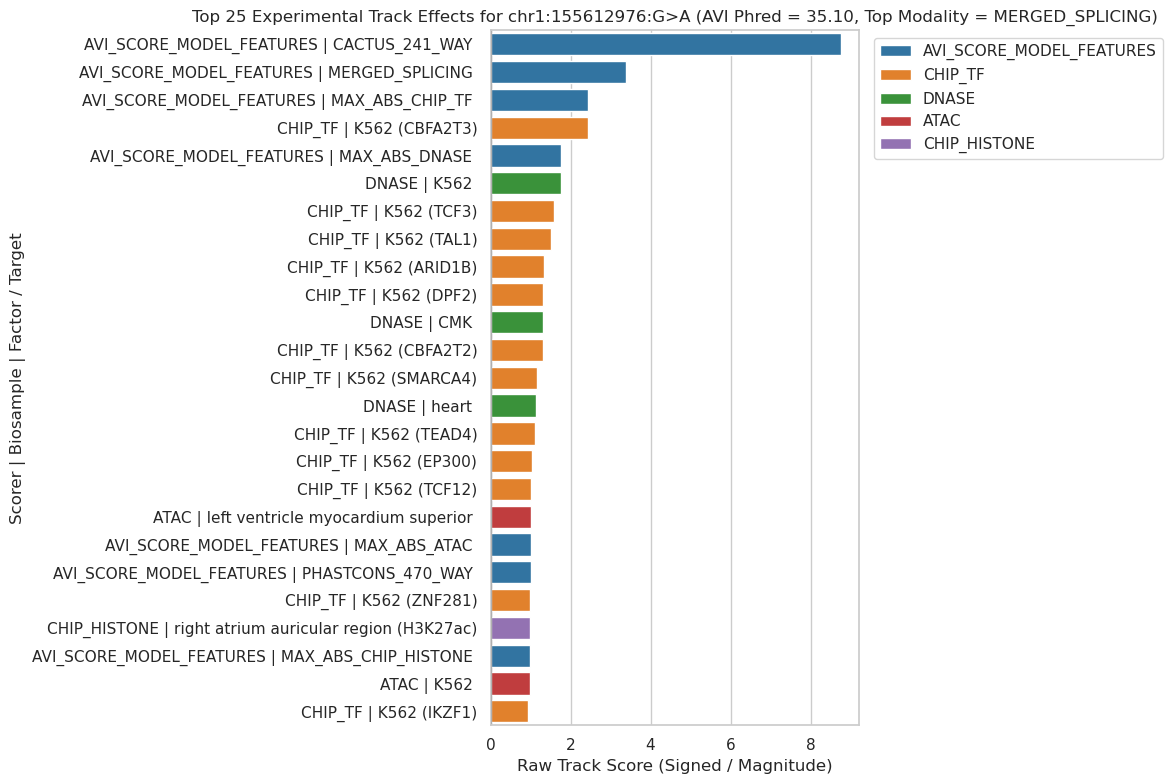

,parquet_column,scorer,score,abs_score,biosample_name,biosample_type,ontology_curie,transcription_factor,histone_mark,gene_suffix,is_cardiac
0,AVI_SCORE_MODEL_FEATURES__t0011,AVI_SCORE_MODEL_FEATURES,8.765000,8.765000,,,,,,,False
1,AVI_SCORE_MODEL_FEATURES__t0000,AVI_SCORE_MODEL_FEATURES,3.393417,3.393417,,,,,,,False
2,AVI_SCORE_MODEL_FEATURES__t0004,AVI_SCORE_MODEL_FEATURES,2.437686,2.437686,,,,,,,False
3,CHIP_TF__t0869,CHIP_TF,2.437686,2.437686,K562,cell_line,EFO:0002067,CBFA2T3,,,False
4,AVI_SCORE_MODEL_FEATURES__t0003,AVI_SCORE_MODEL_FEATURES,1.756901,1.756901,,,,,,,False
5,DNASE__t0118,DNASE,1.756901,1.756901,K562,cell_line,EFO:0002067,,,,False
6,CHIP_TF__t1064,CHIP_TF,1.594995,1.594995,K562,cell_line,EFO:0002067,TCF3,,,False
7,CHIP_TF__t1060,CHIP_TF,1.512052,1.512052,K562,cell_line,EFO:0002067,TAL1,,,False
8,CHIP_TF__t0845,CHIP_TF,1.329417,1.329417,K562,cell_line,EFO:0002067,ARID1B,,,False
9,CHIP_TF__t0897,CHIP_TF,1.318762,1.318762,K562,cell_line,EFO:0002067,DPF2,,,False


In [42]:
# @title Interactive Single-Variant Multi-Assay Track Profiler
def profile_single_variant_tracks(
    variant_str: str,
    top_n: int = 25,
    cardiac_only: bool = False,
) -> pd.DataFrame:
    """Loads all track columns for a single variant, joins with track metadata, and plots top effects."""
    row_df = load_variant_subset(
        columns=None,
        filter_expr=(ds.field('variant') == variant_str),
    )
    if row_df.empty:
        raise ValueError(f'Variant {variant_str!r} not found in Parquet dataset.')

    row = row_df.iloc[0]
    track_cols = schema_tracks_df['parquet_column'].tolist()
    avail_track_cols = [c for c in track_cols if c in row_df.columns]

    long_df = pd.DataFrame({
        'parquet_column': avail_track_cols,
        'score': row[avail_track_cols].to_numpy(dtype=np.float32),
    }).dropna(subset=['score'])
    long_df['abs_score'] = long_df['score'].abs()

    long_df = long_df.merge(schema_tracks_df, on='parquet_column', how='left')
    if cardiac_only:
        long_df = long_df[long_df['is_cardiac'].fillna(False)].copy()

    long_df = long_df.sort_values('abs_score', ascending=False).reset_index(drop=True)

    # Plot top N tracks for this variant
    top_sub = long_df.head(top_n).copy()
    if not top_sub.empty:
        top_sub['display_label'] = [
            f"{r['scorer']} | {r['biosample_name'] or r['track_name']} "
            f"{('(' + r['histone_mark'] + ')') if r['histone_mark'] else ''}"
            f"{('(' + r['transcription_factor'] + ')') if r['transcription_factor'] else ''}"
            f"{(' [' + r['gene_suffix'] + ']') if r['gene_suffix'] else ''}"
            for _, r in top_sub.iterrows()
        ]
        plt.figure(figsize=(12, max(5, 0.32 * len(top_sub))))
        sns.barplot(
            data=top_sub,
            x='score',
            y='display_label',
            hue='scorer',
            dodge=False,
            palette='tab10',
        )
        plt.axvline(0, color='black', linewidth=0.8)
        plt.title(
            f"Top {len(top_sub)} Experimental Track Effects for {variant_str} "
            f"(AVI Phred = {float(row.get('avi_phred', np.nan)):.2f}, Top Modality = {row.get('top_modality', 'N/A')})"
        )
        plt.xlabel('Raw Track Score (Signed / Magnitude)')
        plt.ylabel('Scorer | Biosample | Factor / Target')
        plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
        plt.tight_layout()
        plt.show()

    return long_df


# Profile the #1 highest-Phred variant automatically
top_variant_id = str(top_variants_df['variant'].iloc[0])
print(f'Profiling #1 variant: {top_variant_id}')
print(f'AlphaGenome Atlas link: {build_atlas_variant_url(top_variant_id)}')
top_variant_profile_df = profile_single_variant_tracks(top_variant_id, top_n=25)
display(
    top_variant_profile_df[
        [
            'parquet_column',
            'scorer',
            'score',
            'abs_score',
            'biosample_name',
            'biosample_type',
            'ontology_curie',
            'transcription_factor',
            'histone_mark',
            'gene_suffix',
            'is_cardiac',
        ]
    ].head(20)
)
